# 04 · A stress test for unseen kinds of AI text, and a steadier classifier
**Report sections:** Generalization (Q4), Model selection (Q1.3-Q1.4), Open-ended improvement (Q5)

Our stress test so far hides a *topic*. On it the blend scores about 0.99, but Kaggle says 0.94. The assignment says
the test set also contains **AI generators we have not seen**, and nothing in our validation setup imitates that.
This notebook adds that missing test, uses it to compare classifier designs, and re-chooses the blend weight.

**Findings (numbers are in the tables below).**
- **Hiding a kind of AI text is a much harder test than hiding a topic.** The notebook-03 classifier scores 0.988 on
  unseen domains but 0.971 on unseen AI kinds, and 0.918 on the hardest kind (AI text that looks like human text on
  every GPT-2 feature).
- **This test moves with Kaggle.** Notebook-02 classifier: unseen kind 0.925, Kaggle 0.914. Notebook-03 classifier:
  0.971 and 0.937. The unseen-domain test rated both near 0.98.
- **The repetition features carry over to a kind never seen in training.** With the repetition-avoiding kind held
  out, the notebook-03 classifier still scores 1.000 on it; the notebook-02 classifier scores 0.915.
- **A simpler, steadier classifier is better on unseen kinds.** The mean of a logistic regression and ten bagged,
  more regularized tree models scores 0.982 (hardest kind 0.946), against 0.971 (0.918) for the single tree model,
  at almost no cost on unseen domains (0.987 vs 0.988).
- **Blend with the SVM:** unseen kind 0.988, hardest kind 0.963 (notebook-03 blend: 0.980 and 0.945).
- **Not yet known:** the Kaggle score of the new files.

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split, load_test
from src.models import make_model
from src.features import has_blank_line_breaks
from src.evaluate import auroc, predict_proba1, log_result, savefig, save_predictions, write_submission

from domain_eval import TopicDomains, domain_stress_test, mean_auroc_by_domain
from kind_eval import AIKinds, kind_stress_test, blend_unseen_kind, kind_weight_curve
from src.lm_features import FEATURES, load_cached
from src.repetition_features import RP_FEATURES, WORD_FEATURES, load_cached as load_repetition
from src.lm_model import lm_boost, lm_logreg, lm_linear_plus_trees, blend, blend_by_domain
from plots import plot_weight_curve

set_seed(SEED)
pd.set_option("display.width", 220)

In [3]:
train_df, val_df = get_split()
test_df = load_test()
y_tr, y_va = train_df["label"].to_numpy(), val_df["label"].to_numpy()
feats = load_cached().join(load_repetition().drop(columns="file"))
ALL = FEATURES + RP_FEATURES + WORD_FEATURES

# SVM scores saved by notebook 02 (standard and unseen-domain), so those fits are not repeated here.
val_scores = pd.read_csv(RESULTS_DIR / "joling_scores_val.csv")
train_unseen = pd.read_csv(RESULTS_DIR / "joling_scores_train_unseen.csv")
S = val_scores[val_scores.model == "svm"].set_index("id").loc[val_df["id"]]
S_tr = train_unseen[train_unseen.model == "svm"].set_index("id").loc[train_df["id"]]
domains = TopicDomains(k=8).fit(train_df["text"])
dom_tr, dom_va = domains.predict(train_df["text"]), domains.predict(val_df["text"])
assert (dom_va == S["domain"].to_numpy()).all()

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


## Step 1 · Kinds of AI text
We have no generator labels, so we group the AI **training** texts by their GPT-2 features (k-means, 4 groups).
Texts in a group were probably produced by similar generators or settings. Human texts are not grouped.

In [4]:
KIND_FEATURES = FEATURES + RP_FEATURES
kinds = AIKinds(k=4).fit(feats.loc[train_df["id"][y_tr == 1], KIND_FEATURES])
kind_tr = kinds.assign(feats.loc[train_df["id"], KIND_FEATURES], y_tr)
kind_va = kinds.assign(feats.loc[val_df["id"], KIND_FEATURES], y_va)

show = ["ll_mean", "ll_std", "top1", "rp_deficit", "hapax_share", "the_share", "n_tokens"]
profile = feats.loc[train_df["id"], show].groupby(np.where(kind_tr < 0, "humans", "AI kind " + kind_tr.astype(str))).mean()
profile.insert(0, "n_val", pd.Series(np.where(kind_va < 0, "humans", "AI kind " + kind_va.astype(str))).value_counts())
profile.insert(0, "n_train", pd.Series(np.where(kind_tr < 0, "humans", "AI kind " + kind_tr.astype(str))).value_counts())
profile.to_csv(RESULTS_DIR / "joling_ai_kinds.csv")
profile.round(3)

,n_train,n_val,ll_mean,ll_std,top1,rp_deficit,hapax_share,the_share,n_tokens
AI kind 0,1235,277,-3.066,2.603,0.389,0.048,0.784,0.045,251.843
AI kind 1,294,61,-0.686,1.468,0.863,-0.057,0.501,0.041,397.099
AI kind 2,644,162,-4.728,2.928,0.187,0.263,0.934,0.008,275.457
AI kind 3,1827,500,-2.130,2.120,0.528,-0.033,0.683,0.056,272.142
humans,4000,1000,-3.291,2.835,0.376,-0.045,0.710,0.053,272.206


**Reading the table** (compare each row with `humans`). One kind is far more predictable than human text
(`ll_mean` near 0, `top1` very high). One avoids repetition (`rp_deficit` high, almost no "the"). One is ordinary
smooth AI text. And one is **close to human text on every feature**: that one should be the hardest.

## Step 2 · Hold out one kind at a time
Train on all human texts plus the AI texts of the other kinds; test on the held-out kind against all validation
humans (layout removed). "Seen" is the same test with the model trained on everything.

In [5]:
MODELS = {
    "svm (robust_svm_tuned)": lambda: make_model("robust_svm_tuned"),
    "02 classifier: trees, 24 predictability features": lambda: lm_boost(max_depth=3, learning_rate=0.1, columns=FEATURES),
    "03 classifier: trees, 54 features": lambda: lm_boost(max_depth=3, learning_rate=0.1, columns=ALL),
    "linear, 54 features": lambda: lm_logreg(1.0, columns=ALL),
    "linear + bagged careful trees, 54 features": lambda: lm_linear_plus_trees(columns=ALL),
}
kind_summary, kind_tables, kind_preds = {}, {}, {}
for name, make in MODELS.items():
    print(name)
    kind_summary[name], kind_tables[name], kind_preds[name] = kind_stress_test(make, train_df, val_df, kind_tr, kind_va)
pd.concat([p.assign(model=m) for m, p in kind_preds.items()]).to_csv(RESULTS_DIR / "joling_scores_val_unseen_kind.csv", index=False)
by_kind = pd.concat({m: t.set_index("kind")["unseen"] for m, t in kind_tables.items()}, axis=1).T
by_kind.columns = [f"unseen: kind {c}" for c in by_kind.columns]
by_kind.round(4)

svm (robust_svm_tuned)


  kind 0: seen 0.9638 -> unseen 0.9465


  kind 1: seen 0.9962 -> unseen 0.9893


  kind 2: seen 0.9949 -> unseen 0.9770


  kind 3: seen 0.9793 -> unseen 0.9321
02 classifier: trees, 24 predictability features


  kind 0: seen 0.9395 -> unseen 0.8294


... (12 outputs left out)

  kind 1: seen 0.9997 -> unseen 0.9988


  kind 2: seen 0.9995 -> unseen 0.9967


  kind 3: seen 0.9954 -> unseen 0.9855


,unseen: kind 0,unseen: kind 1,unseen: kind 2,unseen: kind 3
svm (robust_svm_tuned),0.9465,0.9893,0.9770,0.9321
"02 classifier: trees, 24 predictability features",0.8294,0.9993,0.9145,0.9566
"03 classifier: trees, 54 features",0.9181,0.9996,1.0000,0.9677
"linear, 54 features",0.9416,0.9844,0.9656,0.9783
"linear + bagged careful trees, 54 features",0.9461,0.9988,0.9967,0.9855


## Step 3 · All three stress tests side by side
For each classifier: standard validation, unseen domain (notebook `01`), unseen AI kind (this notebook), and the
Kaggle public score where we have one.

In [6]:
KAGGLE = {"02 classifier: trees, 24 predictability features": 0.91396, "03 classifier: trees, 54 features": 0.93716}
rows, dom_val, dom_train = [], {}, {}
for name, make in MODELS.items():
    if name.startswith("svm"):                       # saved by notebook 02
        row = {"train_auroc": 1.0, "val_auroc": auroc(y_va, S["p_layout_removed"]),
               "unseen_domain": mean_auroc_by_domain(y_va, S["p_unseen_layout_removed"], dom_va)}
    else:
        summ, _, preds = domain_stress_test(make, train_df, val_df, dom_tr, dom_va, verbose=False, score_train=True)
        dom_train[name] = preds.attrs.pop("train_unseen")
        dom_val[name] = preds
        row = {"train_auroc": auroc(y_tr, predict_proba1(make().fit(train_df["text"], y_tr), train_df["text"])),
               "val_auroc": summ["val_layout_removed"], "unseen_domain": summ["unseen_layout_removed_mean"]}
    row.update({"unseen_ai_kind": kind_summary[name]["unseen_kind_mean"],
                "hardest_unseen_kind": kind_summary[name]["hardest_unseen_kind"], "kaggle_public": KAGGLE.get(name, np.nan)})
    rows.append({"model": name, **row})
three = pd.DataFrame(rows)
three.to_csv(RESULTS_DIR / "joling_three_stress_tests.csv", index=False)
three.round(4)

,model,train_auroc,val_auroc,unseen_domain,unseen_ai_kind,hardest_unseen_kind,kaggle_public
0,svm (robust_svm_tuned),1.0000,0.9786,0.9328,0.9612,0.9321,NaN
1,"02 classifier: trees, 24 predictability features",0.9942,0.9794,0.9761,0.9249,0.8294,0.9140
2,"03 classifier: trees, 54 features",0.9998,0.9908,0.9880,0.9714,0.9181,0.9372
3,"linear, 54 features",0.9850,0.9833,0.9803,0.9675,0.9416,NaN
4,"linear + bagged careful trees, 54 features",0.9941,0.9890,0.9871,0.9818,0.9461,NaN


**Which classifier?** The four language-model classifiers are within 0.002 of each other on unseen domains, so the
unseen-kind column decides. This comparison uses validation labels (that is what the validation set is for), so the
chosen model's validation numbers are slightly optimistic.

In [7]:
lm_rows = three[~three.model.str.startswith("svm") & three.model.str.contains("54")].copy()
lm_rows["mean_of_unseen_tests"] = (lm_rows["unseen_domain"] + lm_rows["unseen_ai_kind"]) / 2
CHOSEN = lm_rows.sort_values("mean_of_unseen_tests").iloc[-1]["model"]
print("chosen classifier:", CHOSEN)
lm_rows[["model", "unseen_domain", "unseen_ai_kind", "mean_of_unseen_tests"]].round(4)

chosen classifier: linear + bagged careful trees, 54 features


,model,unseen_domain,unseen_ai_kind,mean_of_unseen_tests
2,"03 classifier: trees, 54 features",0.9880,0.9714,0.9797
3,"linear, 54 features",0.9803,0.9675,0.9739
4,"linear + bagged careful trees, 54 features",0.9871,0.9818,0.9844


## Step 4 · Blend weight from both unseen tests, training rows only
Notebook `03` chose the weight on unseen *domains* only (0.8). Now we also look at unseen *kinds*. Both curves are
computed on training rows (see `kind_weight_curve` for how the kind curve avoids scoring humans the model trained
on), and the weight is the one with the best average of the two.

  kind 0, half 0 done


  kind 0, half 1 done


  kind 1, half 0 done


  kind 1, half 1 done


  kind 2, half 0 done


  kind 2, half 1 done


  kind 3, half 0 done


  kind 3, half 1 done
kind curve: 216s
chosen weight of the classifier: 0.8


,lm_weight,unseen_domain,unseen_ai_kind,mean_of_both,hardest_kind
0,0.0,0.9340,0.9472,0.9406,0.9179
1,0.1,0.9471,0.9587,0.9529,0.9344
2,0.2,0.9585,0.9678,0.9631,0.9494
3,0.3,0.9684,0.9748,0.9716,0.9580
4,0.4,0.9764,0.9800,0.9782,0.9624
5,0.5,0.9822,0.9833,0.9828,0.9645
6,0.6,0.9861,0.9852,0.9857,0.9645
7,0.7,0.9883,0.9858,0.9871,0.9626
8,0.8,0.9890,0.9855,0.9873,0.9590
9,0.9,0.9887,0.9841,0.9864,0.9537


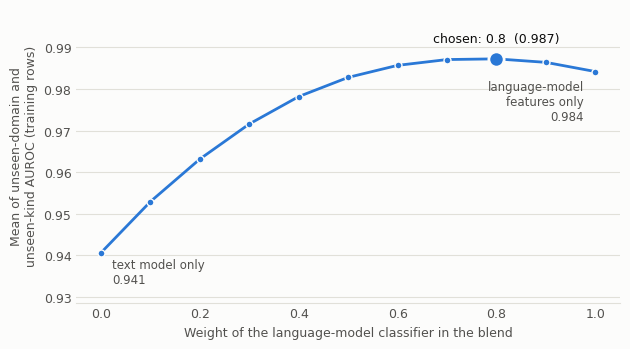

In [8]:
weights = np.round(np.arange(0, 1.01, 0.1), 1)
L_tr = dom_train[CHOSEN]
dom_curve = np.array([mean_auroc_by_domain(y_tr, blend_by_domain(S_tr["p_unseen_layout_removed"], L_tr["p_unseen"], dom_tr, w), dom_tr)
                      for w in weights])
t0 = time.time()
kc = kind_weight_curve(lambda: make_model("robust_svm_tuned"), MODELS[CHOSEN], train_df, kind_tr, weights)
print(f"kind curve: {time.time() - t0:.0f}s")
kind_curve = kc[[float(w) for w in weights]].mean().to_numpy()
hardest_curve = kc.groupby("kind")[[float(w) for w in weights]].mean().min().to_numpy()

curves = pd.DataFrame({"lm_weight": weights, "unseen_domain": dom_curve, "unseen_ai_kind": kind_curve,
                       "mean_of_both": (dom_curve + kind_curve) / 2, "hardest_kind": hardest_curve})
curves.to_csv(RESULTS_DIR / "joling_blend_weights_04.csv", index=False)
W = float(weights[int(np.argmax(curves["mean_of_both"]))])
print("chosen weight of the classifier:", W)
fig = plot_weight_curve(weights, curves["mean_of_both"], W)
fig.axes[0].set_ylabel("Mean of unseen-domain and\nunseen-kind AUROC (training rows)")
savefig(fig, "joling_blend_weight_04")
curves.round(4)

In [9]:
def blank_push(p, texts, push=0.1):
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (np.asarray(p) + push * b) / (1 + push)


def blend_numbers(lm_name, w):
    # All with layout removed, so the blank-line boost plays no part here.
    Lv, Kv, Ks = dom_val[lm_name], kind_preds[lm_name], kind_preds["svm (robust_svm_tuned)"]
    per_kind = blend_unseen_kind(Ks, Kv, w)
    return {"val_auroc": auroc(y_va, blend(S["p_layout_removed"], Lv["p_layout_removed"], w)),
            "unseen_domain": mean_auroc_by_domain(y_va, blend_by_domain(S["p_unseen_layout_removed"], Lv["p_unseen_layout_removed"], dom_va, w), dom_va),
            "unseen_ai_kind": float(per_kind.mean()), "hardest_unseen_kind": float(per_kind.min())}


KAGGLE_BLEND = {"02 blend (w=0.6)": 0.93600}
blends = pd.DataFrame({
    "svm alone": {"val_auroc": auroc(y_va, S["p_layout_removed"]), "unseen_domain": mean_auroc_by_domain(y_va, S["p_unseen_layout_removed"], dom_va),
                  "unseen_ai_kind": kind_summary["svm (robust_svm_tuned)"]["unseen_kind_mean"],
                  "hardest_unseen_kind": kind_summary["svm (robust_svm_tuned)"]["hardest_unseen_kind"]},
    "02 blend (w=0.6)": blend_numbers("02 classifier: trees, 24 predictability features", 0.6),
    "03 blend (w=0.8)": blend_numbers("03 classifier: trees, 54 features", 0.8),
    f"04 blend (w={W})": blend_numbers(CHOSEN, W),
}).T.rename_axis("model").reset_index()
blends["kaggle_public (without blank-line boost)"] = blends["model"].map(KAGGLE_BLEND)
blends.to_csv(RESULTS_DIR / "joling_blend_04.csv", index=False)
for _, r in blends.iterrows():
    log_result("joling_blend_04_log", {"model": r["model"], "classifier": CHOSEN, "lm_weight": W, "seed": SEED},
               {c: r[c] for c in ["val_auroc", "unseen_domain", "unseen_ai_kind", "hardest_unseen_kind"]})
blends.round(4)

,model,val_auroc,unseen_domain,unseen_ai_kind,hardest_unseen_kind,kaggle_public (without blank-line boost)
0,svm alone,0.9786,0.9328,0.9612,0.9321,NaN
1,02 blend (w=0.6),0.9934,0.9866,0.9746,0.9381,0.936
2,03 blend (w=0.8),0.9948,0.9909,0.9800,0.9454,NaN
3,04 blend (w=0.8),0.9933,0.9900,0.9877,0.9630,NaN


## Step 5 · Train on all 10,000 labelled rows and write the Kaggle files

In [10]:
full_df = pd.concat([train_df, val_df], ignore_index=True)
lm_all = MODELS[CHOSEN]().fit(full_df["text"], full_df["label"])
svm_all = make_model("robust_svm_tuned").fit(full_df["text"], full_df["label"])
t_lm, t_svm = predict_proba1(lm_all, test_df["text"]), predict_proba1(svm_all, test_df["text"])
t_blend_blank = blend(blank_push(t_svm, test_df["text"]), t_lm, W)

Lv = dom_val[CHOSEN]
save_predictions("joling_lm_04", val_df, Lv["p_standard"], test_df, t_lm)
save_predictions("joling_blend_04_blank", val_df, blend(blank_push(S["p_standard"], val_df["text"]), Lv["p_standard"], W), test_df, t_blend_blank)
write_submission(test_df, t_lm, tag="joling_lm_04")
write_submission(test_df, t_blend_blank, tag="joling_blend_04_blank");

saved results/preds_joling_lm_04.csv
saved results/preds_joling_blend_04_blank.csv
wrote submissions/submission_20261110_223628_joling_lm_04.csv (3000 rows) - validated OK
wrote submissions/submission_20261110_223628_joling_blend_04_blank.csv (3000 rows) - validated OK


## What we learned
1. A validation scheme is only as good as the shift it imitates. Hiding topics told us the models were fine; hiding
   kinds of AI text showed the gap, and it is the one of our tests whose ranking of classifiers agrees with the two
   Kaggle scores we have for them.
2. Tree models are sharp on what they have seen and brittle on what they have not: the single tree model has the
   best validation score (0.991) and the worst unseen-kind score of the 54-feature models. The linear model is the
   opposite. Averaging the two keeps most of both.
3. The hardest case is AI text that GPT-2 finds as unpredictable as human writing and that does not avoid repetition.
   No model here is strong on it when it is unseen (best single model 0.946), and the SVM is as good as the
   language-model classifiers there, which is why the SVM still earns a place in the blend.

## Limits
- Our "kinds" are k-means groups on GPT-2 features, a stand-in for real generator labels; a truly new generator may
  differ from all four in ways these groups do not cover.
- The classifier was picked using validation labels (five candidates), so its validation numbers are a little
  optimistic. The blend weight was picked on training rows only.
- The weight curve is flat near its top: 0.7 and 0.8 differ by 0.0002 on the mean of the two tests, while the hardest
  kind prefers 0.5-0.6 (0.9645 vs 0.9590 at 0.8). We kept the rule fixed before looking (best mean), which gives 0.8.
- Two Kaggle scores agreeing with the unseen-kind test is encouraging, not proof.

## Next
Upload `submission_<time>_joling_blend_04_blank.csv` and compare with 0.941 (notebook-02 blend with the blank-line
boost). A newer language model for the features is the most direct way to attack the hardest kind.